<a href="https://colab.research.google.com/github/tudorostin/audio-activity-classification/blob/main/tema1IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# integrare google drive
from google.colab import drive
drive.mount('/content/drive')

from google.colab import drive
import os
import zipfile

# montare drive
drive.mount('/content/drive')

# dezarhivare
zip_path = '/content/drive/MyDrive/ML_Audio/student_dataset.zip'

print("Dezarhivare in curs...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/')
print("Dezarhivare completă! Mediul de lucru a fost refăcut.")


Mounted at /content/drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dezarhivare in curs...
Dezarhivare completă! Mediul de lucru a fost refăcut.


In [ ]:
import librosa
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm
import warnings

# ignorare advertismente fisiere scurte/zgomot
warnings.filterwarnings('ignore')

def extract_features(y, sr=16000):
    # param din enunt
    frame_length = 512
    hop_length = 160

    features = {}

    # --- 1. Trasaturi de nivel (RMS si Factor de creasta) ---
    rms_total = np.sqrt(np.mean(y**2))
    features['rms_dbfs'] = 20 * np.log10(rms_total + 1e-9)

    peak_val = np.max(np.abs(y))
    features['crest_factor_db'] = 20 * np.log10(peak_val / (rms_total + 1e-9) + 1e-9)

    # --- 2. Zgomot de fond, Semnal si SNR ---
    rms_frames = librosa.feature.rms(y=y, frame_length=frame_length, hop_length=hop_length)[0]
    rms_db_frames = 20 * np.log10(rms_frames + 1e-9)

    noise_db = np.percentile(rms_db_frames, 10)  # Zgomot estimat (percentila 10)
    signal_db = np.percentile(rms_db_frames, 95) # Semnal estimat (percentila 95)

    features['background_noise_db'] = noise_db
    features['snr_db'] = signal_db - noise_db

    # --- 3. Ponderea cadrelor active ---
    max_frame_db = np.max(rms_db_frames)
    active_frames_count = np.sum(rms_db_frames >= (max_frame_db - 20))
    features['active_frame_ratio'] = active_frames_count / len(rms_db_frames)

    # --- 4. Descriptori spectrali ---
    S, _ = librosa.magphase(librosa.stft(y, n_fft=frame_length, hop_length=hop_length))
    energy_per_frame = np.sum(S, axis=0)

    centroid = librosa.feature.spectral_centroid(S=S, sr=sr)[0]
    bandwidth = librosa.feature.spectral_bandwidth(S=S, sr=sr)[0]
    rolloff = librosa.feature.spectral_rolloff(S=S, sr=sr, roll_percent=0.85)[0]
    flatness = librosa.feature.spectral_flatness(S=S)[0]
    zcr = librosa.feature.zero_crossing_rate(y, frame_length=frame_length, hop_length=hop_length)[0]

    # calcul medii (ponderate cu energia acolo unde are sens fizic)
    sum_energy = np.sum(energy_per_frame) + 1e-9
    features['spectral_centroid_mean'] = np.average(centroid, weights=energy_per_frame) if sum_energy > 1e-8 else np.mean(centroid)
    features['spectral_bandwidth_mean'] = np.average(bandwidth, weights=energy_per_frame) if sum_energy > 1e-8 else np.mean(bandwidth)
    features['spectral_rolloff_mean'] = np.average(rolloff, weights=energy_per_frame) if sum_energy > 1e-8 else np.mean(rolloff)
    features['spectral_flatness_mean'] = np.mean(flatness)
    features['zcr_mean'] = np.mean(zcr)

    # --- 5. MFCC ---
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20, n_fft=frame_length, hop_length=hop_length)
    for i in range(1, 21):
        features[f'mfcc_{i}_mean'] = np.mean(mfccs[i-1])
        features[f'mfcc_{i}_std'] = np.std(mfccs[i-1])

    return features

In [ ]:
# cale dataset
dataset_path = '/content'
metadata_path = os.path.join(dataset_path, 'metadata.csv')

df_meta = pd.read_csv(metadata_path)

all_features = []

# Folosim tqdm pentru a vedea o bara de progres
print("Începem extragerea trăsăturilor...")
for index, row in tqdm(df_meta.iterrows(), total=df_meta.shape[0]):
    # cale completa fisier audio
    audio_path = os.path.join(dataset_path, row['filename'])

    try:
        y, sr = librosa.load(audio_path, sr=16000)

        # extragere trasaturi
        features = extract_features(y, sr)

        # adaugare metadate
        features['filename'] = row['filename']
        features['label'] = row['label']
        features['split'] = row['split']
        features['source_id'] = row['source_id']

        all_features.append(features)

    except Exception as e:
        print(f"Eroare la procesarea {audio_path}: {e}")

# creare dataFrame
df_features = pd.DataFrame(all_features)

# reordonare coloane ca sa am mai intai label split si source_id
cols = ['filename', 'label', 'split', 'source_id'] + [c for c in df_features.columns if c not in ['filename', 'label', 'split', 'source_id']]
df_features = df_features[cols]

# salvare csv in drive
output_csv = '/content/drive/MyDrive/ML_Audio/extracted_features.csv'
df_features.to_csv(output_csv, index=False)
print(f"Extragere completă! Fișierul a fost salvat la: {output_csv}")

# afisare date
display(df_features.head())

Începem extragerea trăsăturilor...


  0%|          | 0/1537 [00:00<?, ?it/s]

Extragere completă! Fișierul a fost salvat la: /content/drive/MyDrive/ML_Audio/extracted_features.csv


,filename,label,split,source_id,rms_dbfs,crest_factor_db,background_noise_db,snr_db,active_frame_ratio,spectral_centroid_mean,...,mfcc_16_mean,mfcc_16_std,mfcc_17_mean,mfcc_17_std,mfcc_18_mean,mfcc_18_std,mfcc_19_mean,mfcc_19_std,mfcc_20_mean,mfcc_20_std
0,audio/Cough/00038.wav,Cough,train,446491,-16.360409,15.445495,-55.313713,46.423382,0.407960,1748.230387,...,1.353105,12.757237,2.005413,8.803883,0.400499,8.591790,0.889783,9.554586,3.885680,9.208050
1,audio/Cough/00084.wav,Cough,train,252219,-16.457436,15.542521,-62.165264,55.272026,0.139303,1247.290208,...,-2.465636,6.671332,-2.603635,8.085921,1.393240,5.947509,0.883199,6.688997,-1.620718,6.679265
2,audio/Cough/00159.wav,Cough,train,461571,-20.699884,19.784676,-54.559097,40.023537,0.353234,2059.551525,...,-2.578995,9.030810,7.568763,11.229258,2.922246,12.507103,1.368192,10.747428,2.212217,8.932070
3,audio/Cough/00217.wav,Cough,train,410493,-16.697741,15.782532,-32.188183,21.705448,0.532338,1465.159266,...,1.082037,10.786063,8.836199,8.371957,6.525593,7.760393,3.982555,6.862561,6.577979,7.514739
4,audio/Cough/00293.wav,Cough,train,317439,-19.648726,18.733810,-48.437851,36.104275,0.452736,2959.909674,...,5.273642,8.038682,-1.691100,9.181461,4.645869,7.779169,-9.108109,8.705643,0.969512,6.856333


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import os

# unde salvez graficele
output_dir = '/content/drive/MyDrive/ML_Audio/Grafice_EDA'
os.makedirs(output_dir, exist_ok=True)

# incarcare date si filtrare sa am doar din train
df_features = pd.read_csv('/content/drive/MyDrive/ML_Audio/extracted_features.csv')
df_train = df_features[df_features['split'] == 'train'].copy()

# 2. distributia tuturor trasaturilor scalare pe clase (boxplot uri)
print("Generare și salvare Boxplots...")

# Extragem toate coloanele numerice
numeric_cols = df_train.select_dtypes(include=['float64', 'int64']).columns
# Filtrăm: păstrăm DOAR trăsăturile scalare (fără MFCC și fără source_id)
features_to_plot = [col for col in numeric_cols if 'mfcc' not in col and col != 'source_id']

for feature in features_to_plot:
    plt.figure(figsize=(10, 6))
    # Folosim o paletă diferită (ex: 'husl' sau 'muted') pentru a te diferenția vizual
    sns.boxplot(data=df_train, x='label', y=feature, palette='husl')
    plt.xticks(rotation=45, ha='right')
    plt.title(f'Distribuția {feature} pe clase')
    plt.tight_layout()

    file_path = os.path.join(output_dir, f'boxplot_{feature}.png')
    plt.savefig(file_path, dpi=300)
    plt.close()

# 3. matricea de corelatie
print("Generare și salvare Matrice de Corelație...")
df_numeric = df_train[numeric_cols]

plt.figure(figsize=(24, 20))
corr_matrix = df_numeric.corr()

# xticklabels=True și yticklabels=True pentru afișarea numelor
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, xticklabels=True, yticklabels=True)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.title('Matricea de corelație a tuturor trăsăturilor', fontsize=16)
plt.tight_layout()

file_path = os.path.join(output_dir, 'matrice_corelatie.png')
plt.savefig(file_path, dpi=300)
plt.close()

# 4. proiectii 2D ale MFCC (PCA si t-SNE)
print("Generare și salvare Proiecții 2D (PCA & t-SNE)...")
mfcc_cols = [col for col in df_numeric.columns if 'mfcc' in col]
X_mfcc = df_train[mfcc_cols]
y_labels = df_train['label']

scaler = StandardScaler()
X_mfcc_scaled = scaler.fit_transform(X_mfcc)

# PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_mfcc_scaled)

plt.figure(figsize=(10, 8))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_labels, palette='tab20', s=50, alpha=0.7)
plt.title('Proiecție PCA (2D) a trăsăturilor MFCC')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'proiectie_pca.png'), dpi=300)
plt.close()

# t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_mfcc_scaled)

plt.figure(figsize=(10, 8))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_labels, palette='tab20', s=50, alpha=0.7)
plt.title('Proiecție t-SNE (2D) a trăsăturilor MFCC')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'proiectie_tsne.png'), dpi=300)
plt.close()

print("Proces finalizat. Verificați folderul din Google Drive.")

Generare și salvare Boxplots...
Generare și salvare Matrice de Corelație...
Generare și salvare Proiecții 2D (PCA & t-SNE)...
Proces finalizat. Verificați folderul din Google Drive.


In [ ]:
import pandas as pd
from sklearn.model_selection import PredefinedSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# 1. incarcare set date
df_features = pd.read_csv('/content/drive/MyDrive/ML_Audio/extracted_features.csv')

# 2. formare train val si test separand cu coloana split
train_mask = df_features['split'] == 'train'
val_mask = df_features['split'] == 'val'
test_mask = df_features['split'] == 'test'

# definesc trasaturile si etichetele eliminad metadatele
drop_cols = ['filename', 'label', 'split', 'source_id']

X_train = df_features[train_mask].drop(columns=drop_cols)
y_train = df_features[train_mask]['label']
source_id_train = df_features[train_mask]['source_id'] # pt cross-validation

X_val = df_features[val_mask].drop(columns=drop_cols)
y_val = df_features[val_mask]['label']

X_test = df_features[test_mask].drop(columns=drop_cols)
y_test = df_features[test_mask]['label']

print(f"Dimensiuni X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"Dimensiuni X_val: {X_val.shape}, y_val: {y_val.shape}")
print(f"Dimensiuni X_test: {X_test.shape}, y_test: {y_test.shape}")

# 3. Pipeline pt cei 3 algoritmi
# Setez class_weight='balanced' din cauza dezechilibrului claselor

pipelines = {
    'LogisticRegression': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42))
    ]),

    'SVM': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', SVC(class_weight='balanced', probability=True, random_state=42))
    ]),

    'RandomForest': Pipeline([
        ('scaler', StandardScaler()), # Nu este strict necesar pentru RF, dar păstrează consistența codului
        ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42))
    ])
}

print("\nModelele de bază au fost definite cu succes în Pipelines!")

Dimensiuni X_train: (1229, 50), y_train: (1229,)
Dimensiuni X_val: (154, 50), y_val: (154,)
Dimensiuni X_test: (154, 50), y_test: (154,)

Modelele de bază au fost definite cu succes în Pipelines!


In [ ]:
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from scipy.stats import loguniform, randint
import numpy as np

# 1. kFold grupand dupa 'source_id'
gkf = GroupKFold(n_splits=5)

# 2. definire hiperparametrii
param_grids = {
    'LogisticRegression': {
        'classifier__C': loguniform(1e-3, 1e2),  # pt regularizare cautare logaritmica
        'classifier__solver': ['lbfgs', 'saga']
    },
    'SVM': {
        'classifier__C': loguniform(1e-2, 1e2),
        'classifier__gamma': ['scale', 'auto'] + list(loguniform(1e-4, 1e-1).rvs(size=3, random_state=42)),
        'classifier__kernel': ['rbf', 'linear']
    },
    'RandomForest': {
        'classifier__n_estimators': randint(100, 500),
        'classifier__max_depth': [None, 10, 20, 30],
        'classifier__min_samples_split': randint(2, 11)
    }
}

# 3. dictionar pt salvare cele mai bune modele
best_models = {}
search_results = {}

print("Începem antrenarea și căutarea hiperparametrilor. Acest proces va dura câteva minute...\n")

for model_name, pipeline in pipelines.items():
    print(f"--- Antrenare {model_name} ---")

    # RandomizedSearchCV pentru a gasi cei mai buni hiperparametri
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_grids[model_name],
        n_iter=15,          # Cauta prin 15 combinatii aleatoare pentru fiecare model
        scoring='f1_macro', # Optimizam pentru F1-macro din cauza dezechilibrului claselor
        cv=gkf,             # Cross-validation cu grupare dupa source_id
        n_jobs=-1,          # Foloseste toate nucleele procesorului
        random_state=42,
        verbose=1
    )

    # ANTRENARAE PROPRIU-ZISA!
    # Trebuie sa trecem 'groups=source_id_train' pentru ca GroupKFold sa stie cum sa imparta datele
    search.fit(X_train, y_train, groups=source_id_train)

    # Salvare cel mai bun rezultat
    best_models[model_name] = search.best_estimator_
    search_results[model_name] = search

    print(f"Cel mai bun scor F1-macro pe validare (CV): {search.best_score_:.4f}")
    print(f"Cei mai buni hiperparametri: {search.best_params_}\n")

print("Antrenarea și căutarea hiperparametrilor s-a încheiat cu succes!")

Începem antrenarea și căutarea hiperparametrilor. Acest proces va dura câteva minute...

--- Antrenare LogisticRegression ---
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Cel mai bun scor F1-macro pe validare (CV): 0.5823
Cei mai buni hiperparametri: {'classifier__C': np.float64(0.16949768237884735), 'classifier__solver': 'lbfgs'}

--- Antrenare SVM ---
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Cel mai bun scor F1-macro pe validare (CV): 0.6109
Cei mai buni hiperparametri: {'classifier__C': np.float64(8.471801418819979), 'classifier__gamma': np.float64(0.015702970884055395), 'classifier__kernel': 'rbf'}

--- Antrenare RandomForest ---
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Cel mai bun scor F1-macro pe validare (CV): 0.6082
Cei mai buni hiperparametri: {'classifier__max_depth': None, 'classifier__min_samples_split': 8, 'classifier__n_estimators': 221}

Antrenarea și căutarea hiperparametrilor s-a încheiat cu succes!


=== SUMAR IMPACT HIPERPARAMETRI ȘI PERFORMANȚĂ (CV / VAL / TEST) ===


,Model,CV F1-macro (Min),CV F1-macro (Median),CV F1-macro (Best),CV Std (Best),Amplitudine (Max - Min),VAL Acc,VAL F1-macro,TEST Acc,TEST F1-macro
0,LogisticRegression,0.4371,0.5612,0.5823,0.0202,0.1452,0.5909,0.5812,0.5390,0.5248
1,SVM,0.0340,0.5448,0.6109,0.0137,0.5768,0.5909,0.5589,0.6169,0.6019
2,RandomForest,0.5838,0.6021,0.6082,0.0282,0.0244,0.5455,0.4911,0.5909,0.5848



=== DETALII IMPACT HIPERPARAMETRI ===

--- LogisticRegression (Top 5 vs Bottom 3 combinații) ---


,param_classifier__C,param_classifier__solver,mean_test_score,std_test_score,rank_test_score
3,0.169498,lbfgs,0.582319,0.020182,1
12,0.144453,lbfgs,0.578708,0.022334,2
0,0.074593,lbfgs,0.578677,0.020590,3
13,0.420604,lbfgs,0.576576,0.022295,4
5,0.046617,saga,0.574766,0.018501,5
4,0.001952,saga,0.475510,0.035335,13
7,0.001915,saga,0.473255,0.034015,14
9,0.001009,saga,0.437103,0.029848,15


LR - Medie/Max F1-macro pe solver:
                          count     min    mean     max
param_classifier__solver                               
lbfgs                         6  0.5658  0.5748  0.5823
saga                          9  0.4371  0.5183  0.5748

--- SVM (Top 5 vs Bottom 3 combinații) ---


,param_classifier__C,param_classifier__gamma,param_classifier__kernel,mean_test_score,std_test_score,rank_test_score
1,8.471801,0.015703,rbf,0.610884,0.013662,1
11,1.140086,scale,rbf,0.605810,0.026054,2
12,27.527174,0.015703,rbf,0.597036,0.020232,3
10,0.147428,0.001329,linear,0.595196,0.033510,4
4,0.037279,0.001329,linear,0.590517,0.035059,5
2,0.042080,0.001329,rbf,0.041330,0.039870,13
8,0.010672,scale,rbf,0.036136,0.036822,14
13,0.018206,0.071145,rbf,0.034047,0.029848,15


SVM - Medie/Max F1-macro pe tip de kernel:
                          count     min    mean     max
param_classifier__kernel                               
linear                        7  0.5322  0.5644  0.5952
rbf                           8  0.0340  0.3136  0.6109

--- RandomForest (Top 5 vs Bottom 3 combinații) ---


,param_classifier__max_depth,param_classifier__min_samples_split,param_classifier__n_estimators,mean_test_score,std_test_score,rank_test_score
2,None,8,221,0.608237,0.028234,1
1,20,9,288,0.605412,0.041525,2
9,30,7,352,0.604086,0.027779,3
5,30,9,251,0.603993,0.042190,4
6,20,7,408,0.603442,0.030804,5
10,30,10,148,0.595906,0.034815,13
7,10,9,393,0.594077,0.032485,14
8,10,6,260,0.583818,0.035376,15


RF - Medie/Max F1-macro pe max_depth:
           count     min    mean     max
depth_str                               
10             2  0.5838  0.5889  0.5941
20             8  0.5971  0.6018  0.6054
30             3  0.5959  0.6013  0.6041
None           2  0.5985  0.6034  0.6082


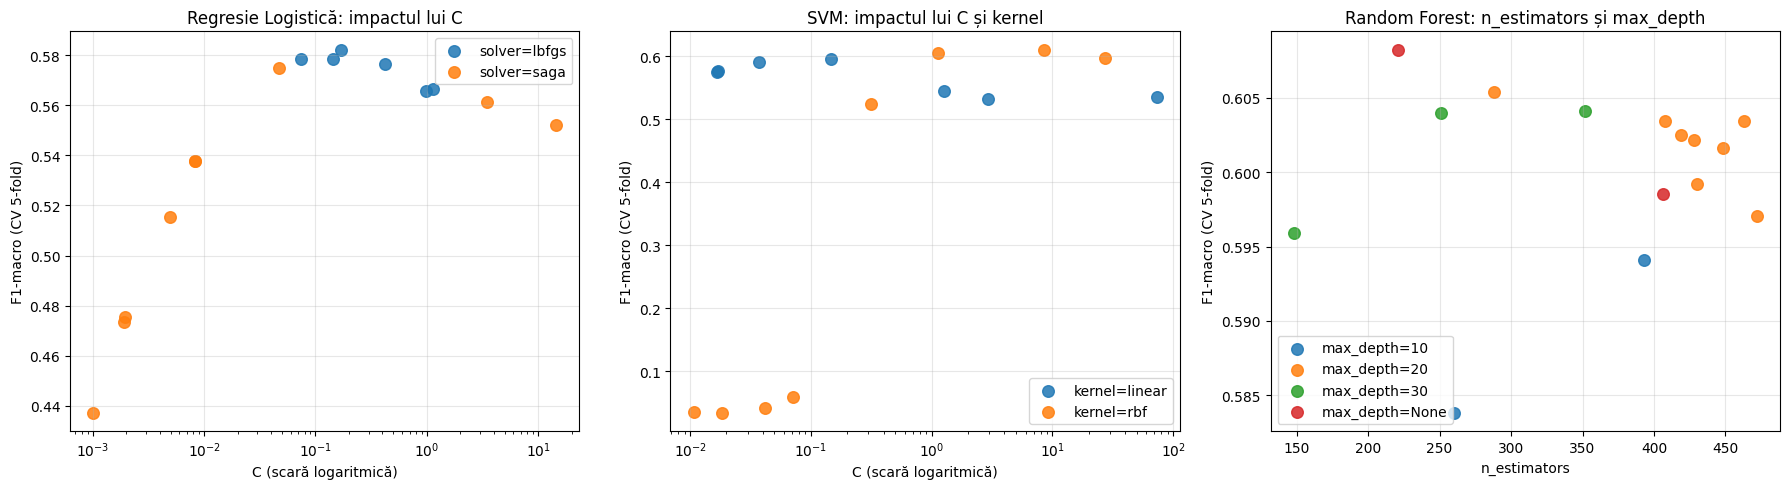

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

eval_dir = '/content/drive/MyDrive/ML_Audio/Evaluare_Modele'
os.makedirs(eval_dir, exist_ok=True)

# 1. Tabel centralizat: Impactul hiperparametrilor (CV) + Comparatie CV vs VAL vs TEST
summary_rows = []

for model_name, search in search_results.items():
    cv_df = pd.DataFrame(search.cv_results_)
    scores = cv_df['mean_test_score']
    best_idx = search.best_index_
    best_std = cv_df.loc[best_idx, 'std_test_score']

    model = best_models[model_name]
    y_val_pred = model.predict(X_val)
    y_test_pred = model.predict(X_test)

    summary_rows.append({
        'Model': model_name,
        'CV F1-macro (Min)': round(scores.min(), 4),
        'CV F1-macro (Median)': round(scores.median(), 4),
        'CV F1-macro (Best)': round(search.best_score_, 4),
        'CV Std (Best)': round(best_std, 4),
        'Amplitudine (Max - Min)': round(scores.max() - scores.min(), 4),
        'VAL Acc': round(accuracy_score(y_val, y_val_pred), 4),
        'VAL F1-macro': round(f1_score(y_val, y_val_pred, average='macro'), 4),
        'TEST Acc': round(accuracy_score(y_test, y_test_pred), 4),
        'TEST F1-macro': round(f1_score(y_test, y_test_pred, average='macro'), 4),
    })

df_summary = pd.DataFrame(summary_rows)
print("=== SUMAR IMPACT HIPERPARAMETRI ȘI PERFORMANȚĂ (CV / VAL / TEST) ===")
display(df_summary)

# 2. Detalii per hiperparametru pentru fiecare model
print("\n=== DETALII IMPACT HIPERPARAMETRI ===")
for model_name, search in search_results.items():
    cv_df = pd.DataFrame(search.cv_results_)
    param_cols = [c for c in cv_df.columns if c.startswith('param_')]
    cols_to_show = param_cols + ['mean_test_score', 'std_test_score', 'rank_test_score']
    print(f"\n--- {model_name} (Top 5 vs Bottom 3 combinații) ---")
    sorted_df = cv_df[cols_to_show].sort_values('rank_test_score')
    display(pd.concat([sorted_df.head(5), sorted_df.tail(3)]))

    if model_name == 'SVM':
        print("SVM - Medie/Max F1-macro pe tip de kernel:")
        print(cv_df.groupby('param_classifier__kernel')['mean_test_score'].agg(['count', 'min', 'mean', 'max']).round(4))
    elif model_name == 'LogisticRegression':
        print("LR - Medie/Max F1-macro pe solver:")
        print(cv_df.groupby('param_classifier__solver')['mean_test_score'].agg(['count', 'min', 'mean', 'max']).round(4))
    elif model_name == 'RandomForest':
        cv_df['depth_str'] = cv_df['param_classifier__max_depth'].fillna('None').astype(str)
        print("RF - Medie/Max F1-macro pe max_depth:")
        print(cv_df.groupby('depth_str')['mean_test_score'].agg(['count', 'min', 'mean', 'max']).round(4))

# 3. Grafic cu impactul hiperparametrilor principali (3 panouri)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Logistic Regression (C vs F1-macro CV)
lr_df = pd.DataFrame(search_results['LogisticRegression'].cv_results_)
for solver, grp in lr_df.groupby('param_classifier__solver'):
    axes[0].scatter(grp['param_classifier__C'], grp['mean_test_score'], label=f"solver={solver}", s=70, alpha=0.85)
axes[0].set_xscale('log')
axes[0].set_title('Regresie Logistică: impactul lui C')
axes[0].set_xlabel('C (scară logaritmică)')
axes[0].set_ylabel('F1-macro (CV 5-fold)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Panel 2: SVM (C & kernel vs F1-macro CV)
svm_df = pd.DataFrame(search_results['SVM'].cv_results_)
for kernel, grp in svm_df.groupby('param_classifier__kernel'):
    axes[1].scatter(grp['param_classifier__C'], grp['mean_test_score'], label=f"kernel={kernel}", s=70, alpha=0.85)
axes[1].set_xscale('log')
axes[1].set_title('SVM: impactul lui C și kernel')
axes[1].set_xlabel('C (scară logaritmică)')
axes[1].set_ylabel('F1-macro (CV 5-fold)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Panel 3: Random Forest (n_estimators & max_depth vs F1-macro CV)
rf_df = pd.DataFrame(search_results['RandomForest'].cv_results_)
rf_df['depth_str'] = rf_df['param_classifier__max_depth'].fillna('None').astype(str)
for depth, grp in rf_df.groupby('depth_str'):
    axes[2].scatter(grp['param_classifier__n_estimators'], grp['mean_test_score'], label=f"max_depth={depth}", s=70, alpha=0.85)
axes[2].set_title('Random Forest: n_estimators și max_depth')
axes[2].set_xlabel('n_estimators')
axes[2].set_ylabel('F1-macro (CV 5-fold)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(eval_dir, 'impact_hiperparametri_cv.png'), dpi=300)
plt.show()

In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# cale unde voi salva graficele
eval_dir = '/content/drive/MyDrive/ML_Audio/Evaluare_Modele'
os.makedirs(eval_dir, exist_ok=True)

# Preluare nume clase
classes = sorted(df_features['label'].unique())

print("=== EVALUARE MODELE PE SETURILE DE VALIDARE ȘI TEST ===\n")

for model_name, model in best_models.items():
    print(f"================ {model_name} ================")

    # 1. Evaluare pe Setul de Validare (val)
    y_val_pred = model.predict(X_val)
    acc_val = accuracy_score(y_val, y_val_pred)
    f1_val = f1_score(y_val, y_val_pred, average='macro')

    # 2. Evaluare pe Setul de Test (test)
    y_test_pred = model.predict(X_test)
    acc_test = accuracy_score(y_test, y_test_pred)
    f1_test = f1_score(y_test, y_test_pred, average='macro')

    print("--- Performanțe Globale ---")
    print(f"VALIDARE -> Acuratețe: {acc_val:.4f} | F1-macro: {f1_val:.4f}")
    print(f"TEST     -> Acuratețe: {acc_test:.4f} | F1-macro: {f1_test:.4f}\n")

    print("--- Raport de Clasificare pe Setul de TEST (Precizie și Recall per clasă) ---")
    # classification_report genereaza direct precizia, recall-ul si F1 per clasa
    print(classification_report(y_test, y_test_pred))
    print("\n" + "="*50 + "\n")

    print("--- Raport de Clasificare pe Setul de VAL (Precizie și Recall per clasă) ---")
    # classification_report genereaza direct precizia, recall-ul si F1 per clasa
    print(classification_report(y_val, y_val_pred))
    print("\n" + "="*50 + "\n")

    # 3. Matricea de confuzie normalizata pe randuri (adevarul)
    cm = confusion_matrix(y_test, y_test_pred, normalize='true')

    plt.figure(figsize=(10, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
    disp.plot(cmap='Blues', xticks_rotation=45, values_format='.2f', ax=plt.gca())
    plt.title(f'Matrice de confuzie normalizată (Test) - {model_name}')
    plt.tight_layout()

    # Salvarea matricelor ca imagine
    file_path = os.path.join(eval_dir, f'matrice_confuzie_{model_name}.png')
    plt.savefig(file_path, dpi=300)
    plt.close()

print(f"Generarea metricilor este completă! Matricele de confuzie au fost salvate în folderul: {eval_dir}")

=== EVALUARE MODELE PE SETURILE DE VALIDARE ȘI TEST ===

================ LogisticRegression ================
--- Performanțe Globale ---
VALIDARE -> Acuratețe: 0.5909 | F1-macro: 0.5812
TEST     -> Acuratețe: 0.5390 | F1-macro: 0.5248

--- Raport de Clasificare pe Setul de TEST (Precizie și Recall per clasă) ---
                  precision    recall  f1-score   support

           Cough       0.56      0.67      0.61        15
   DoorOpenClose       0.50      0.47      0.48        15
 DrawerOpenClose       0.40      0.36      0.38        11
       KeyJingle       0.78      0.64      0.70        11
  KeyboardTyping       0.45      0.56      0.50         9
           Knock       0.75      0.92      0.83        13
MouseButtonClick       0.27      0.43      0.33         7
       PaperTear       0.56      0.38      0.45        13
            Pour       0.76      0.87      0.81        15
    SwitchToggle       0.57      0.53      0.55        15
            Walk       0.17      0.13      0.1

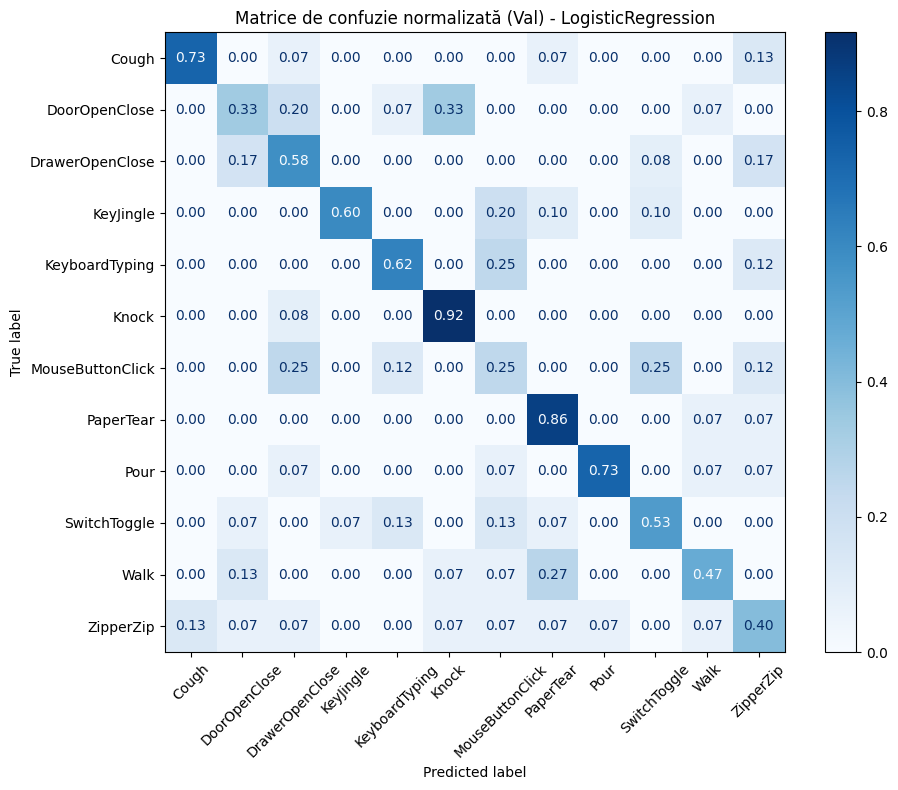

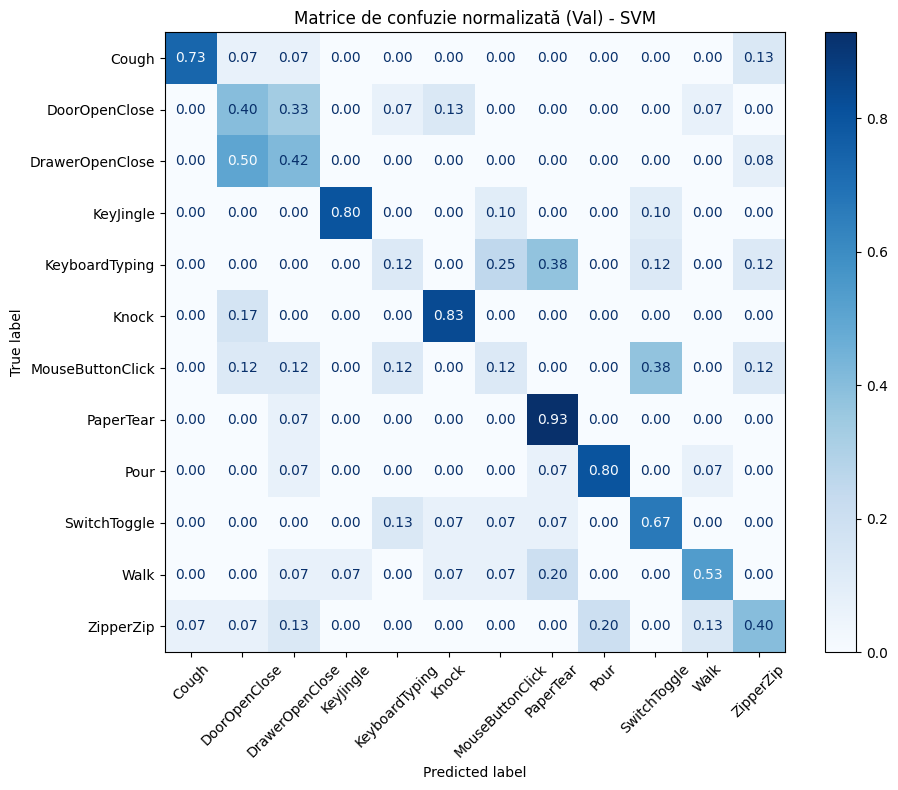

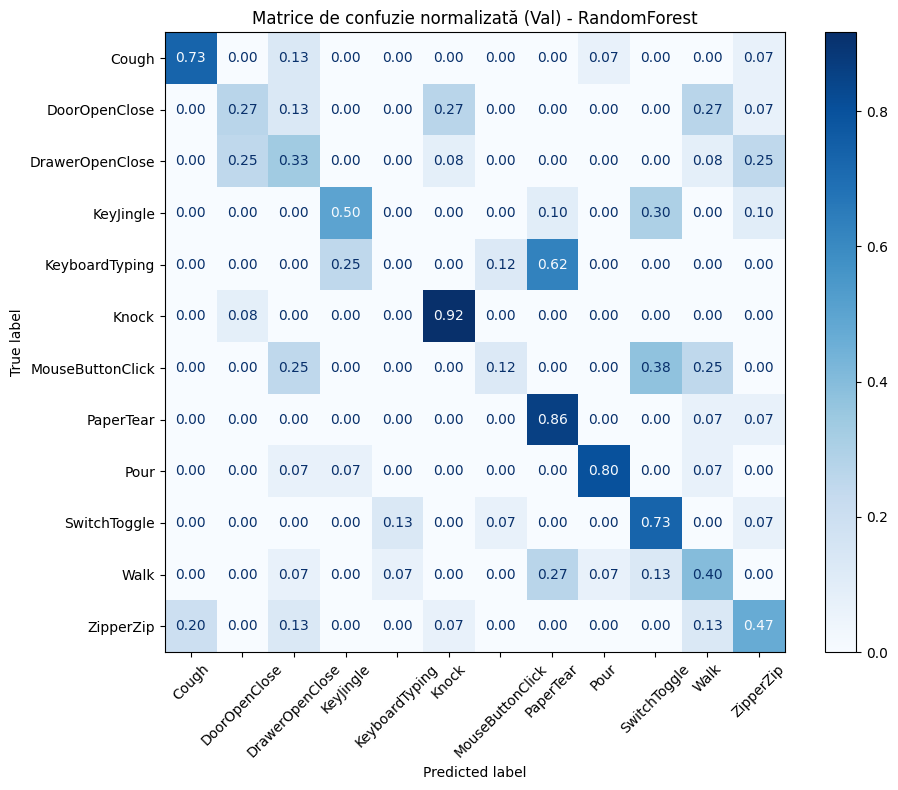

Matricele de confuzie pentru VAL au fost salvate cu succes!


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

classes = sorted(df_features['label'].unique())

for model_name, model in best_models.items():
    y_val_pred = model.predict(X_val)
    cm_val = confusion_matrix(y_val, y_val_pred, normalize='true')

    plt.figure(figsize=(10, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm_val, display_labels=classes)
    disp.plot(cmap='Blues', xticks_rotation=45, values_format='.2f', ax=plt.gca())
    plt.title(f'Matrice de confuzie normalizată (Val) - {model_name}')
    plt.tight_layout()

    file_path = os.path.join(eval_dir, f'matrice_confuzie_val_{model_name}.png')
    plt.savefig(file_path, dpi=300)
    plt.show()
    plt.close()

print("Matricele de confuzie pentru VAL au fost salvate cu succes!")

In [ ]:
for model_name, model in best_models.items():
    for split_name, X_split, y_split in [('VAL', X_val, y_val), ('TEST', X_test, y_test)]:
        y_pred = model.predict(X_split)
        rep = classification_report(y_split, y_pred, output_dict=True)
        df_rep = pd.DataFrame(rep).transpose().round(2)


        df_rep['support'] = df_rep['support'].astype(int)

        print(f"\n=== {model_name} - {split_name} ===")
        display(df_rep)


=== LogisticRegression - VAL ===


,precision,recall,f1-score,support
Cough,0.85,0.73,0.79,15
DoorOpenClose,0.45,0.33,0.38,15
DrawerOpenClose,0.44,0.58,0.50,12
KeyJingle,0.86,0.60,0.71,10
KeyboardTyping,0.56,0.62,0.59,8
Knock,0.61,0.92,0.73,12
MouseButtonClick,0.18,0.25,0.21,8
PaperTear,0.60,0.86,0.71,14
Pour,0.92,0.73,0.81,15
SwitchToggle,0.67,0.53,0.59,15



=== LogisticRegression - TEST ===


,precision,recall,f1-score,support
Cough,0.56,0.67,0.61,15
DoorOpenClose,0.50,0.47,0.48,15
DrawerOpenClose,0.40,0.36,0.38,11
KeyJingle,0.78,0.64,0.70,11
KeyboardTyping,0.45,0.56,0.50,9
Knock,0.75,0.92,0.83,13
MouseButtonClick,0.27,0.43,0.33,7
PaperTear,0.56,0.38,0.45,13
Pour,0.76,0.87,0.81,15
SwitchToggle,0.57,0.53,0.55,15



=== SVM - VAL ===


,precision,recall,f1-score,support
Cough,0.92,0.73,0.81,15
DoorOpenClose,0.35,0.40,0.38,15
DrawerOpenClose,0.29,0.42,0.34,12
KeyJingle,0.89,0.80,0.84,10
KeyboardTyping,0.20,0.12,0.15,8
Knock,0.71,0.83,0.77,12
MouseButtonClick,0.17,0.12,0.14,8
PaperTear,0.62,0.93,0.74,14
Pour,0.80,0.80,0.80,15
SwitchToggle,0.67,0.67,0.67,15


... (2 outputs left out)


=== RandomForest - VAL ===


,precision,recall,f1-score,support
Cough,0.79,0.73,0.76,15
DoorOpenClose,0.50,0.27,0.35,15
DrawerOpenClose,0.29,0.33,0.31,12
KeyJingle,0.62,0.50,0.56,10
KeyboardTyping,0.00,0.00,0.00,8
Knock,0.65,0.92,0.76,12
MouseButtonClick,0.33,0.12,0.18,8
PaperTear,0.55,0.86,0.67,14
Pour,0.86,0.80,0.83,15
SwitchToggle,0.58,0.73,0.65,15



=== RandomForest - TEST ===


,precision,recall,f1-score,support
Cough,0.69,0.60,0.64,15
DoorOpenClose,0.47,0.47,0.47,15
DrawerOpenClose,0.38,0.45,0.42,11
KeyJingle,0.80,0.73,0.76,11
KeyboardTyping,0.71,0.56,0.62,9
Knock,0.60,0.92,0.73,13
MouseButtonClick,0.75,0.43,0.55,7
PaperTear,0.60,0.46,0.52,13
Pour,0.68,0.87,0.76,15
SwitchToggle,0.75,0.80,0.77,15
